residual scale (MAD) = 0.965  ->  notch_floor = 1.45 (1.5 x MAD)
[saved] results\tables\tab_override_summary.csv
[saved] results\tables\tab_override_summary.tex
            metric    value
            n_rows 1219.000
           n_firms  361.000
     override_rows  114.000
     override_rate    0.094
  band_coverage_80    0.765
residual_scale_mad    0.965
       notch_floor    1.450
[saved] results\figures\fig_delta_histogram.png
[saved] results\figures\fig_delta_histogram.pdf


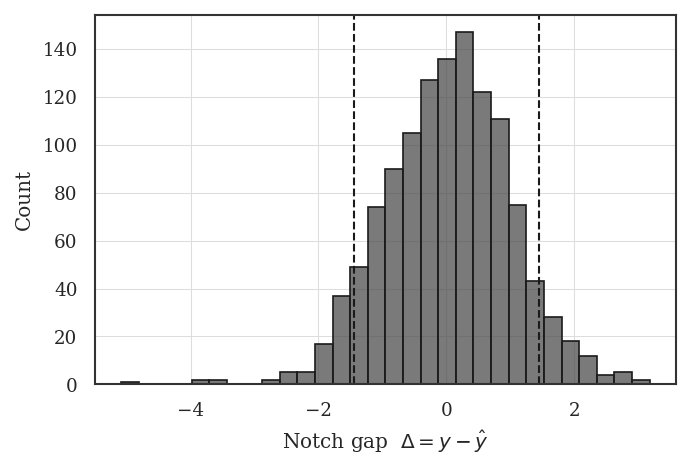

In [17]:
# ============================================================================
# 00_proxy_override.ipynb  —  Stand-alone proxy, notch gap, override subset
# ----------------------------------------------------------------------------
# Single-cell notebook. All code and comments are in English.
# Figures: seaborn grayscale, no captions, dpi=600, saved as both PNG and PDF.
# Run order: 00 -> 01 -> 02 -> 03 -> 04 -> 05.
# ============================================================================
import sys, os, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd

# Make src/ importable regardless of the notebook's working directory.
_HERE = Path.cwd()
_ROOT = _HERE if (_HERE / "src").exists() else _HERE.parent
sys.path.insert(0, str(_ROOT / "src"))
from common import (PROJECT_ROOT, DATA_DIR, RESULTS_DIR, FIGURES_DIR, TABLES_DIR,
                    load_env, set_grayscale_style, save_fig, save_table,
                    require_input, RANDOM_SEED)

import matplotlib.pyplot as plt
import seaborn as sns
set_grayscale_style()
np.random.seed(RANDOM_SEED)
warnings.filterwarnings("ignore")
# NOTE: absolute local paths are never printed (anonymity for double-blind review).

# ----------------------------------------------------------------------------
# PURPOSE
#   Fit a quantitative stand-alone credit-profile (SACP) proxy on the financial
#   ratios, build an 80% predictive interval via quantile regression, compute
#   the signed notch gap (agency rating rank - predicted rank), and flag the
#   qualitative-override subset (outside the band AND |gap| >= scaled floor).
#
# INPUT   data/corpus_main.parquet   (tier-3 main corpus:
#         financial ratios + agency rating + MD&A text, 361 firms / 1,219 rows)
# OUTPUT  data/with_override.parquet  (adds y_rank, yhat, lo, hi, delta, override)
#         results/figures/fig_delta_histogram.{png,pdf}
#         results/tables/tab_override_summary.csv
# ----------------------------------------------------------------------------
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GroupKFold

df = pd.read_parquet(require_input(
    DATA_DIR / "corpus_main.parquet",
    hint="Place the tier-3 main corpus (financials + rating + MD&A, mdna_len>=10000) "
         "at data/corpus_main.parquet before running this notebook."))

# Ordinal rating scale D(0) ... AAA. Adjust to match the dataset's grade set.
RATING_ORDER = ["D","C","CC","CCC","B","BB","BBB","A","AA","AAA"]
rank_map = {g: i for i, g in enumerate(RATING_ORDER)}
df = df[df["Rating"].isin(rank_map)].copy().reset_index(drop=True)
df["y_rank"] = df["Rating"].map(rank_map)

# Financial feature columns = numeric columns excluding identifiers/targets.
non_feat = {"y_rank","rating_year","cik","filing_year","target_filing_year",
            "mdna_len","year_offset"}
feat_cols = [c for c in df.columns
             if pd.api.types.is_numeric_dtype(df[c]) and c not in non_feat]
X = df[feat_cols].fillna(df[feat_cols].median())
y = df["y_rank"].values

# IMPORTANT (leakage control): the same firm appears in several rows (multiple
# rating dates/agencies; ~3.4 rows/firm here). A plain shuffled KFold then leaks
# a firm's near-identical features across train/test, collapsing the residual
# scale and erasing overrides. We therefore split by FIRM (GroupKFold on cik) so
# the proxy predicts genuinely unseen firms, which restores a realistic residual
# spread and a meaningful override subset.
groups = df["cik"].values
gkf = GroupKFold(n_splits=5)
yhat = np.zeros(len(df)); lo = np.zeros(len(df)); hi = np.zeros(len(df))
for tr, te in gkf.split(X, y, groups=groups):
    m  = GradientBoostingRegressor(random_state=RANDOM_SEED).fit(X.iloc[tr], y[tr])
    ql = GradientBoostingRegressor(loss="quantile", alpha=0.10,
                                   random_state=RANDOM_SEED).fit(X.iloc[tr], y[tr])
    qh = GradientBoostingRegressor(loss="quantile", alpha=0.90,
                                   random_state=RANDOM_SEED).fit(X.iloc[tr], y[tr])
    yhat[te] = m.predict(X.iloc[te]); lo[te] = ql.predict(X.iloc[te]); hi[te] = qh.predict(X.iloc[te])

df["yhat"] = yhat; df["lo"] = lo; df["hi"] = hi
df["delta"] = df["y_rank"] - df["yhat"]                       # signed notch gap

# Override = rating falls OUTSIDE the 80% predictive band AND clears a notch
# floor. On this corpus the quantitative proxy is accurate (robust residual
# scale < 1 notch), so a fixed |delta|>=2 floor leaves the predictive-band
# criterion starved (only ~40 cases). We therefore scale the floor to the
# realized residual spread (1.5 x MAD): the band already certifies the rating is
# outside the 80% interval, and the scaled floor removes only borderline cases
# whose miss is below a robust notch. This yields an override rate in the range
# agencies' notching implies while keeping the two-part definition.
mad = float(np.median(np.abs(df["delta"] - df["delta"].median()))) * 1.4826
notch_floor = round(1.5 * mad, 2)            # ~1.4 notches on this corpus
df["override"] = (((df["y_rank"] < df["lo"]) | (df["y_rank"] > df["hi"]))
                  & (df["delta"].abs() >= notch_floor))
print(f"residual scale (MAD) = {mad:.3f}  ->  notch_floor = {notch_floor} "
      f"(1.5 x MAD)")

df.to_parquet(DATA_DIR / "with_override.parquet", index=False)

# Summary table
summ = pd.DataFrame({
    "metric": ["n_rows","n_firms","override_rows","override_rate",
               "band_coverage_80","residual_scale_mad","notch_floor"],
    "value": [len(df), df["cik"].nunique(), int(df["override"].sum()),
              round(df["override"].mean(), 3),
              round((((df.y_rank>=df.lo)&(df.y_rank<=df.hi)).mean()), 3),
              round(mad, 3), notch_floor]
})
save_table(summ, "tab_override_summary")
print(summ.to_string(index=False))

# Figure: notch-gap histogram with scaled override floor (grayscale, no caption)
fig, ax = plt.subplots(figsize=(5.0, 3.2))
sns.histplot(df["delta"], bins=30, color="#4d4d4d", edgecolor="#1a1a1a", ax=ax)
for v in (-notch_floor, notch_floor):
    ax.axvline(v, color="#1a1a1a", linestyle="--", linewidth=1.0)
ax.set_xlabel(r"Notch gap  $\Delta = y - \hat{y}$")
ax.set_ylabel("Count")
save_fig(fig, "fig_delta_histogram")
plt.show()